# DSGym Results Analysis: DAG vs No-DAG
Comparing DAG-guided agents vs standard ReAct across two benchmarks:
- **DSPredict** (Kaggle competitions)
- **DSBio** (biology question-answering)

Models: **claude-sonnet-4-5** · **gpt-5.1**

In [100]:
import json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

plt.rcParams.update({
    "figure.dpi": 120,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})
COLORS = {"dags": "#2196F3", "nodags": "#FF9800"}

# The notebook lives inside evaluation_results/ so Path(".") is the data dir
RESULTS_DIR = Path(".")
DAG_DIR = RESULTS_DIR / "dags"

MODELS = ["claude-sonnet-4-5", "gpt-5.1"]
MODEL_LABELS = {"claude-sonnet-4-5": "Claude Sonnet 4.5", "gpt-5.1": "GPT-5.1"}

DP_RUNS = {
    ("claude-sonnet-4-5", "dags"):   RESULTS_DIR / "dspredict-sampled_litellm_claude-sonnet-4-5_dags_results.json",
    ("claude-sonnet-4-5", "nodags"): RESULTS_DIR / "dspredict-sampled_litellm_claude-sonnet-4-5_nodags_results.json",
    ("gpt-5.1", "dags"):             RESULTS_DIR / "dspredict-sampled_litellm_gpt-5.1_dags_results.json",
    ("gpt-5.1", "nodags"):           RESULTS_DIR / "dspredict-sampled_litellm_gpt-5.1_nodags_results.json",
}

BIO_RUNS = {
    ("claude-sonnet-4-5", "dags"):   RESULTS_DIR / "dsbio-sampled_litellm_claude-sonnet-4-5_dags_results.json",
    ("claude-sonnet-4-5", "nodags"): RESULTS_DIR / "dsbio-sampled_litellm_claude-sonnet-4-5_nodags_results.json",
    ("gpt-5.1", "dags"):             RESULTS_DIR / "dsbio-sampled_litellm_gpt-5.1_dags_results.json",
    ("gpt-5.1", "nodags"):           RESULTS_DIR / "dsbio_litellm_gpt-5.1_nodags_results.json",
}

print("Setup done.")


Setup done.


## 1 · DSPredict Results
Loading without `public_scores` / `scores` to avoid memory issues.

In [101]:
SKIP_LB = {"public_scores", "private_scores", "scores"}

def load_dspredict(path):
    with open(path) as f:
        data = json.load(f)
    rows = []
    for item in data:
        item.pop("raw_response", None)
        ks      = item.get("metrics", {}).get("kaggle_submission", {})
        details = ks.get("details", {})
        lb      = details.get("leaderboard_stats", {})
        for k in SKIP_LB:
            lb.pop(k, None)
        rows.append({
            "sample_id":       item.get("sample_id"),
            "challenge":       details.get("challenge_name"),
            "status":          details.get("status", ""),
            "score":           ks.get("score"),
            "public_medal":    details.get("public_medal", "none"),
            "private_medal":   details.get("private_medal", "none"),
            "pub_percentile":  details.get("public_percentile"),
            "priv_percentile": details.get("private_percentile"),
            "pub_above_med":   details.get("public_above_median"),
            "pub_rank":        details.get("public_rank"),
            "execution_time":  item.get("execution_time"),
            "total_turns":     item.get("total_turns"),
            "success":         item.get("success"),
            "trajectory":      item.get("trajectory", []),
        })
    return rows

dp_data = {}
for key, path in DP_RUNS.items():
    if path.exists():
        dp_data[key] = load_dspredict(path)
        print(f"  {key[0]}/{key[1]}: {len(dp_data[key])} samples loaded")
    else:
        print(f"  MISSING: {path}")


def load_dspredict_from_intermediate(glob_pattern):
    """Load DSPredict results from per-task intermediate checkpoint files.

    Each checkpoint file is a single ``EvaluationResult.to_dict()`` payload saved
    by the evaluator after every task completes (filename format:
    ``{challenge}_{index}_{model_slug}_{dags|nodags}.json``).

    This lets you recover partial results from an incomplete run in the same
    row structure produced by ``load_dspredict``.

    Args:
        glob_pattern: Glob pattern relative to RESULTS_DIR, e.g.
            "*_claude_sonnet_4_5_dags.json"

    Returns:
        List of row dicts with the same keys as ``load_dspredict()``.
    """
    rows = []
    for path in sorted(RESULTS_DIR.glob(glob_pattern)):
        # Skip the aggregate results/summary/config/metrics files
        stem = path.stem
        if any(stem.endswith(s) for s in ("_results", "_summary", "_config", "_metrics")):
            continue
        try:
            with open(path) as f:
                item = json.load(f)
        except Exception:
            continue
        ks      = item.get("metrics", {}).get("kaggle_submission", {})
        details = ks.get("details", {})
        lb      = details.get("leaderboard_stats", {})
        for k in SKIP_LB:
            lb.pop(k, None)
        rows.append({
            "sample_id":       item.get("sample_id"),
            "challenge":       details.get("challenge_name"),
            "status":          details.get("status", ""),
            "score":           ks.get("score"),
            "public_medal":    details.get("public_medal", "none"),
            "private_medal":   details.get("private_medal", "none"),
            "pub_percentile":  details.get("public_percentile"),
            "priv_percentile": details.get("private_percentile"),
            "pub_above_med":   details.get("public_above_median"),
            "pub_rank":        details.get("public_rank"),
            "execution_time":  item.get("execution_time"),
            "total_turns":     item.get("total_turns"),
            "success":         item.get("success"),
            "trajectory":      item.get("trajectory", []),
            "source_file":     str(path),
        })
    print(f"  {len(rows)} intermediate checkpoint(s) loaded from '{glob_pattern}'")
    return rows


# Example — uncomment and adjust the glob pattern to match your run:
# dp_data[("claude-sonnet-4-6", "dags")] = load_dspredict_from_intermediate(
#     "*_claude_sonnet_4_6_dags.json"
# )


  claude-sonnet-4-5/dags: 35 samples loaded
  claude-sonnet-4-5/nodags: 35 samples loaded
  gpt-5.1/dags: 35 samples loaded
  gpt-5.1/nodags: 35 samples loaded


In [102]:
# dp_data[('claude-sonnet-4-5', 'dags')]
  # 'public_medal': 'none',
  # 'private_medal': 'none',
  # 'pub_percentile': None,
  # 'priv_percentile': None,
  # 'pub_above_med': None,
  # 'pub_rank': None,

In [103]:
def dp_summary(dp_data):
    rows = []
    for (model, mode), data in dp_data.items():
        sub    = [r for r in data if "COMPLETE" in str(r.get("status", ""))]
        pcts   = [r["pub_percentile"]  for r in sub if r["pub_percentile"]  is not None]
        prpcts = [r["priv_percentile"] for r in sub if r["priv_percentile"] is not None]
        above  = [r["pub_above_med"]   for r in sub if r["pub_above_med"]   is not None]
        times  = [r["execution_time"]  for r in data if r["execution_time"] is not None]
        turns  = [r["total_turns"]     for r in data if r["total_turns"]    is not None]
        medals = [r["public_medal"]    for r in sub if r["public_medal"] not in (None, "none")]
        rows.append({
            "Model":                   model,
            "Mode":                    mode,
            "N":                       len(data),
            "Coverage (%)":            round(100 * len(sub) / len(data), 1),
            "Medals":                  len(medals),
            "Above Median (%)":        round(100 * sum(above) / len(above), 1) if above else 0,
            "Avg Public Percentile":   round(np.mean(pcts),   2) if pcts   else None,
            "Avg Private Percentile":  round(np.mean(prpcts), 2) if prpcts else None,
            "Median Public Pct":       round(np.median(pcts),   2) if pcts   else None,
            "Median Private Pct":      round(np.median(prpcts), 2) if prpcts else None,
            "Avg Time (min)":          round(np.mean(times) / 60, 1) if times else None,
            "Avg Turns":               round(np.mean(turns), 1)      if turns else None,
        })
    return pd.DataFrame(rows)

dp_sum = dp_summary(dp_data)
print("=== DSPredict Run Summary ===")
display(dp_sum.set_index(["Model", "Mode"]))


=== DSPredict Run Summary ===


N  Coverage (%)  Medals  Above Median (%)  \
Model             Mode                                                 
claude-sonnet-4-5 dags    35          40.0       1               7.1   
                  nodags  35          25.7       1              22.2   
gpt-5.1           dags    35          71.4       1              12.0   
                  nodags  35          82.9       0               3.4   

                          Avg Public Percentile  Avg Private Percentile  \
Model             Mode                                                    
claude-sonnet-4-5 dags                    22.06                   29.50   
                  nodags                  30.81                   20.55   
gpt-5.1           dags                    24.21                   24.72   
                  nodags                  20.63                   19.67   

                          Median Public Pct  Median Private Pct  \
Model             Mode                                            
claude-sonnet-4-5 dags                17.08               26.74   
                  nodags              31.32               18.95   
gpt-5.1           dags                23.89               21.13   
                  nodags              21.12               14.51   

                          Avg Time (min)  Avg Turns  
Model             Mode                               
claude-sonnet-4-5 dags              18.6       13.3  
                  nodags            14.8       14.6  
gpt-5.1           dags              20.0        9.3  
                  nodags            14.4        8.2

In [104]:
dfs = []
for (model, mode), data in dp_data.items():
    df = pd.DataFrame(data).drop(columns=["trajectory"], errors="ignore")
    df["model"] = model
    df["mode"]  = mode
    dfs.append(df)
dp_df = pd.concat(dfs, ignore_index=True)
dp_df["submitted"] = dp_df["status"].str.contains("COMPLETE", na=False)

pivot_pub_pct  = dp_df.pivot_table(index="challenge", columns=["model","mode"], values="pub_percentile",  aggfunc="first")
pivot_priv_pct = dp_df.pivot_table(index="challenge", columns=["model","mode"], values="priv_percentile", aggfunc="first")
pivot_medal    = dp_df.pivot_table(index="challenge", columns=["model","mode"], values="public_medal",    aggfunc="first")

print("=== Per-Challenge PUBLIC Percentile (higher = better) ===")
display(pivot_pub_pct.round(2))
print("\n=== Per-Challenge PRIVATE Percentile (higher = better) ===")
display(pivot_priv_pct.round(2))
print("\n=== Per-Challenge Medal ===")
display(pivot_medal)


=== Per-Challenge PUBLIC Percentile (higher = better) ===


model                                     claude-sonnet-4-5        gpt-5.1  \
mode                                                   dags nodags    dags   
challenge                                                                    
LANL-Earthquake-Prediction                            11.35    NaN   24.01   
career-con-2019                                        0.83    NaN    0.76   
digit-recognizer                                      26.38    NaN   26.98   
elo-merchant-category-recommendation                    NaN    NaN   19.03   
gendered-pronoun-resolution                             NaN  50.00     NaN   
geolifeclef-2024                                        NaN    NaN   35.00   
home-credit-default-risk                                NaN    NaN   27.62   
humpback-whale-identification                          5.09    NaN    3.11   
ieee-fraud-detection                                  22.01    NaN     NaN   
imaterialist-challenge-fashion-2018                   45.54  45.07   45.54   
imaterialist-challenge-furniture-2018                  1.76    NaN   19.44   
m5-forecasting-accuracy                               12.15    NaN    1.75   
mens-march-mania-2022                                   NaN    NaN     NaN   
microsoft-malware-prediction                            NaN    NaN     NaN   
nlp-getting-started                                   29.93    NaN   53.68   
novozymes-enzyme-stability-prediction                   NaN  25.78   15.75   
predict-ai-model-runtime                                NaN    NaN   58.35   
rsna-pneumonia-detection-challenge                      NaN   3.34    3.34   
santander-customer-transaction-prediction             32.06  31.32   36.47   
santander-value-prediction-challenge                  31.29    NaN   29.52   
siim-acr-pneumothorax-segmentation                     3.86   3.86    3.86   
sp-society-camera-model-identification                  NaN    NaN   13.40   
stanford-covid-vaccine                                  NaN    NaN    0.00   
store-sales-time-series-forecasting                     NaN    NaN   25.62   
talkingdata-adtracking-fraud-detection                  NaN    NaN   17.67   
trec-covid-information-retrieval                      85.00    NaN   85.00   
understanding_cloud_organization                        NaN   9.88    7.76   
web-traffic-time-series-forecasting                     NaN  51.60     NaN   
womens-machine-learning-competition-2019                NaN  56.43     NaN   
youtube8m-2018                                          NaN    NaN   23.89   
youtube8m-2019                                         1.58    NaN   27.82   

model                                             
mode                                      nodags  
challenge                                         
LANL-Earthquake-Prediction                 22.81  
career-con-2019                             0.90  
digit-recognizer                           26.71  
elo-merchant-category-recommendation       10.90  
gendered-pronoun-resolution                  NaN  
geolifeclef-2024                            5.00  
home-credit-default-risk                   27.24  
humpback-whale-identification              21.12  
ieee-fraud-detection                       25.63  
imaterialist-challenge-fashion-2018        45.54  
imaterialist-challenge-furniture-2018       1.76  
m5-forecasting-accuracy                    21.34  
mens-march-mania-2022                      46.13  
microsoft-malware-prediction               13.20  
nlp-getting-started                        29.93  
novozymes-enzyme-stability-prediction      15.02  
predict-ai-model-runtime                    0.00  
rsna-pneumonia-detection-challenge          6.98  
santander-customer-transaction-prediction  33.10  
santander-value-prediction-challenge       29.07  
siim-acr-pneumothorax-segmentation          3.86  
sp-society-camera-model-identification       NaN  
stanford-covid-vaccine                      5.50  
store-sales-time-seri


=== Per-Challenge PRIVATE Percentile (higher = better) ===


model                                     claude-sonnet-4-5        gpt-5.1  \
mode                                                   dags nodags    dags   
challenge                                                                    
LANL-Earthquake-Prediction                            17.44    NaN   35.21   
career-con-2019                                        1.18    NaN    1.18   
elo-merchant-category-recommendation                    NaN    NaN   19.22   
gendered-pronoun-resolution                             NaN  26.24     NaN   
geolifeclef-2024                                        NaN    NaN   35.00   
home-credit-default-risk                                NaN    NaN   26.48   
humpback-whale-identification                          5.19    NaN    3.06   
ieee-fraud-detection                                  27.25    NaN     NaN   
imaterialist-challenge-fashion-2018                   45.54  44.60   45.54   
imaterialist-challenge-furniture-2018                 15.69    NaN   19.91   
m5-forecasting-accuracy                               57.47    NaN   61.43   
microsoft-malware-prediction                            NaN    NaN     NaN   
novozymes-enzyme-stability-prediction                   NaN  18.95   22.35   
predict-ai-model-runtime                                NaN    NaN   19.29   
rsna-pneumonia-detection-challenge                      NaN   2.91    2.91   
santander-customer-transaction-prediction             31.16  31.58   35.87   
santander-value-prediction-challenge                  32.32    NaN   30.34   
siim-acr-pneumothorax-segmentation                     9.57   9.57    9.57   
sp-society-camera-model-identification                  NaN    NaN   11.00   
stanford-covid-vaccine                                  NaN    NaN    0.00   
talkingdata-adtracking-fraud-detection                  NaN    NaN   17.44   
trec-covid-information-retrieval                      85.00    NaN   90.00   
understanding_cloud_organization                        NaN   9.98    7.96   
youtube8m-2018                                          NaN    NaN   23.89   
youtube8m-2019                                        26.23    NaN   26.23   

model                                             
mode                                      nodags  
challenge                                         
LANL-Earthquake-Prediction                 48.35  
career-con-2019                             1.18  
elo-merchant-category-recommendation       11.94  
gendered-pronoun-resolution                  NaN  
geolifeclef-2024                            5.00  
home-credit-default-risk                   26.82  
humpback-whale-identification              20.60  
ieee-fraud-detection                       23.43  
imaterialist-challenge-fashion-2018        45.54  
imaterialist-challenge-furniture-2018      15.69  
m5-forecasting-accuracy                    60.22  
microsoft-malware-prediction               14.51  
novozymes-enzyme-stability-prediction       1.17  
predict-ai-model-runtime                    0.00  
rsna-pneumonia-detection-challenge          5.81  
santander-customer-transaction-prediction  32.19  
santander-value-prediction-challenge       30.46  
siim-acr-pneumothorax-segmentation          9.57  
sp-society-camera-model-identification       NaN  
stanford-covid-vaccine                      4.95  
talkingdata-adtracking-fraud-detection     11.84  
trec-covid-information-retrieval           35.00  
understanding_cloud_organization            9.98  
youtube8m-2018                             11.94  
youtube8m-2019                             26.23


=== Per-Challenge Medal ===


model                                     claude-sonnet-4-5        gpt-5.1  \
mode                                                   dags nodags    dags   
challenge                                                                    
LANL-Earthquake-Prediction                             none    NaN    none   
career-con-2019                                        none    NaN    none   
digit-recognizer                                       none    NaN    none   
elo-merchant-category-recommendation                    NaN    NaN    none   
gendered-pronoun-resolution                            none   gold    none   
geolifeclef-2024                                        NaN    NaN    none   
home-credit-default-risk                                NaN    NaN    none   
humpback-whale-identification                          none    NaN    none   
ieee-fraud-detection                                   none    NaN     NaN   
imaterialist-challenge-fashion-2018                    none   none    none   
imaterialist-challenge-furniture-2018                  none    NaN    none   
liverpool-ion-switching                                 NaN    NaN     NaN   
m5-forecasting-accuracy                                none    NaN    none   
mens-machine-learning-competition-2018                  NaN    NaN     NaN   
mens-march-mania-2022                                  none    NaN     NaN   
microsoft-malware-prediction                            NaN    NaN     NaN   
nlp-getting-started                                    none    NaN    none   
novozymes-enzyme-stability-prediction                   NaN   none    none   
predict-ai-model-runtime                                NaN    NaN    none   
rsna-pneumonia-detection-challenge                      NaN   none    none   
santander-customer-transaction-prediction              none   none    none   
santander-value-prediction-challenge                   none    NaN    none   
siim-acr-pneumothorax-segmentation                     none   none    none   
sp-society-camera-model-identification                  NaN    NaN    none   
stanford-covid-vaccine                                  NaN    NaN    none   
store-sales-time-series-forecasting                     NaN    NaN    none   
talkingdata-adtracking-fraud-detection                  NaN    NaN    none   
trec-covid-information-retrieval                     silver    NaN  silver   
understanding_cloud_organization                        NaN   none    none   
web-traffic-time-series-forecasting                     NaN   none    none   
womens-machine-learning-competition-2019                NaN   none    none   
youtube8m-2018                                          NaN    NaN    none   
youtube8m-2019                                         none    NaN    none   

model                                             
mode                                      nodags  
challenge                                         
LANL-Earthquake-Prediction                  none  
career-con-2019                             none  
digit-recognizer                            none  
elo-merchant-category-recommendation        none  
gendered-pronoun-resolution                 none  
geolifeclef-2024                            none  
home-credit-default-risk                    none  
humpback-whale-identification               none  
ieee-fraud-detection                        none  
imaterialist-challenge-fashion-2018         none  
imaterialist-challenge-furniture-2018       none  
liverpool-ion-switching                     none  
m5-forecasting-accuracy                     none  
mens-machine-learning-competition-2018      none  
mens-march-mania-2022                       none  
microsoft-malware-prediction                none  
nlp-getting-started                         none  
novozymes-enzyme-stability-prediction       none  
predict-ai-model-runtime                    none  
rsna-pneumonia-detection-challenge          none  
santander-customer

/var/folders/8g/0gjzsnd56wj1d38gd7pnnglw0000gp/T/ipykernel_2784/1506044565.py:69: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([d for d in pct_data], labels=box_labels, patch_artist=True)
/var/folders/8g/0gjzsnd56wj1d38gd7pnnglw0000gp/T/ipykernel_2784/1506044565.py:69: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([d for d in pct_data], labels=box_labels, patch_artist=True)


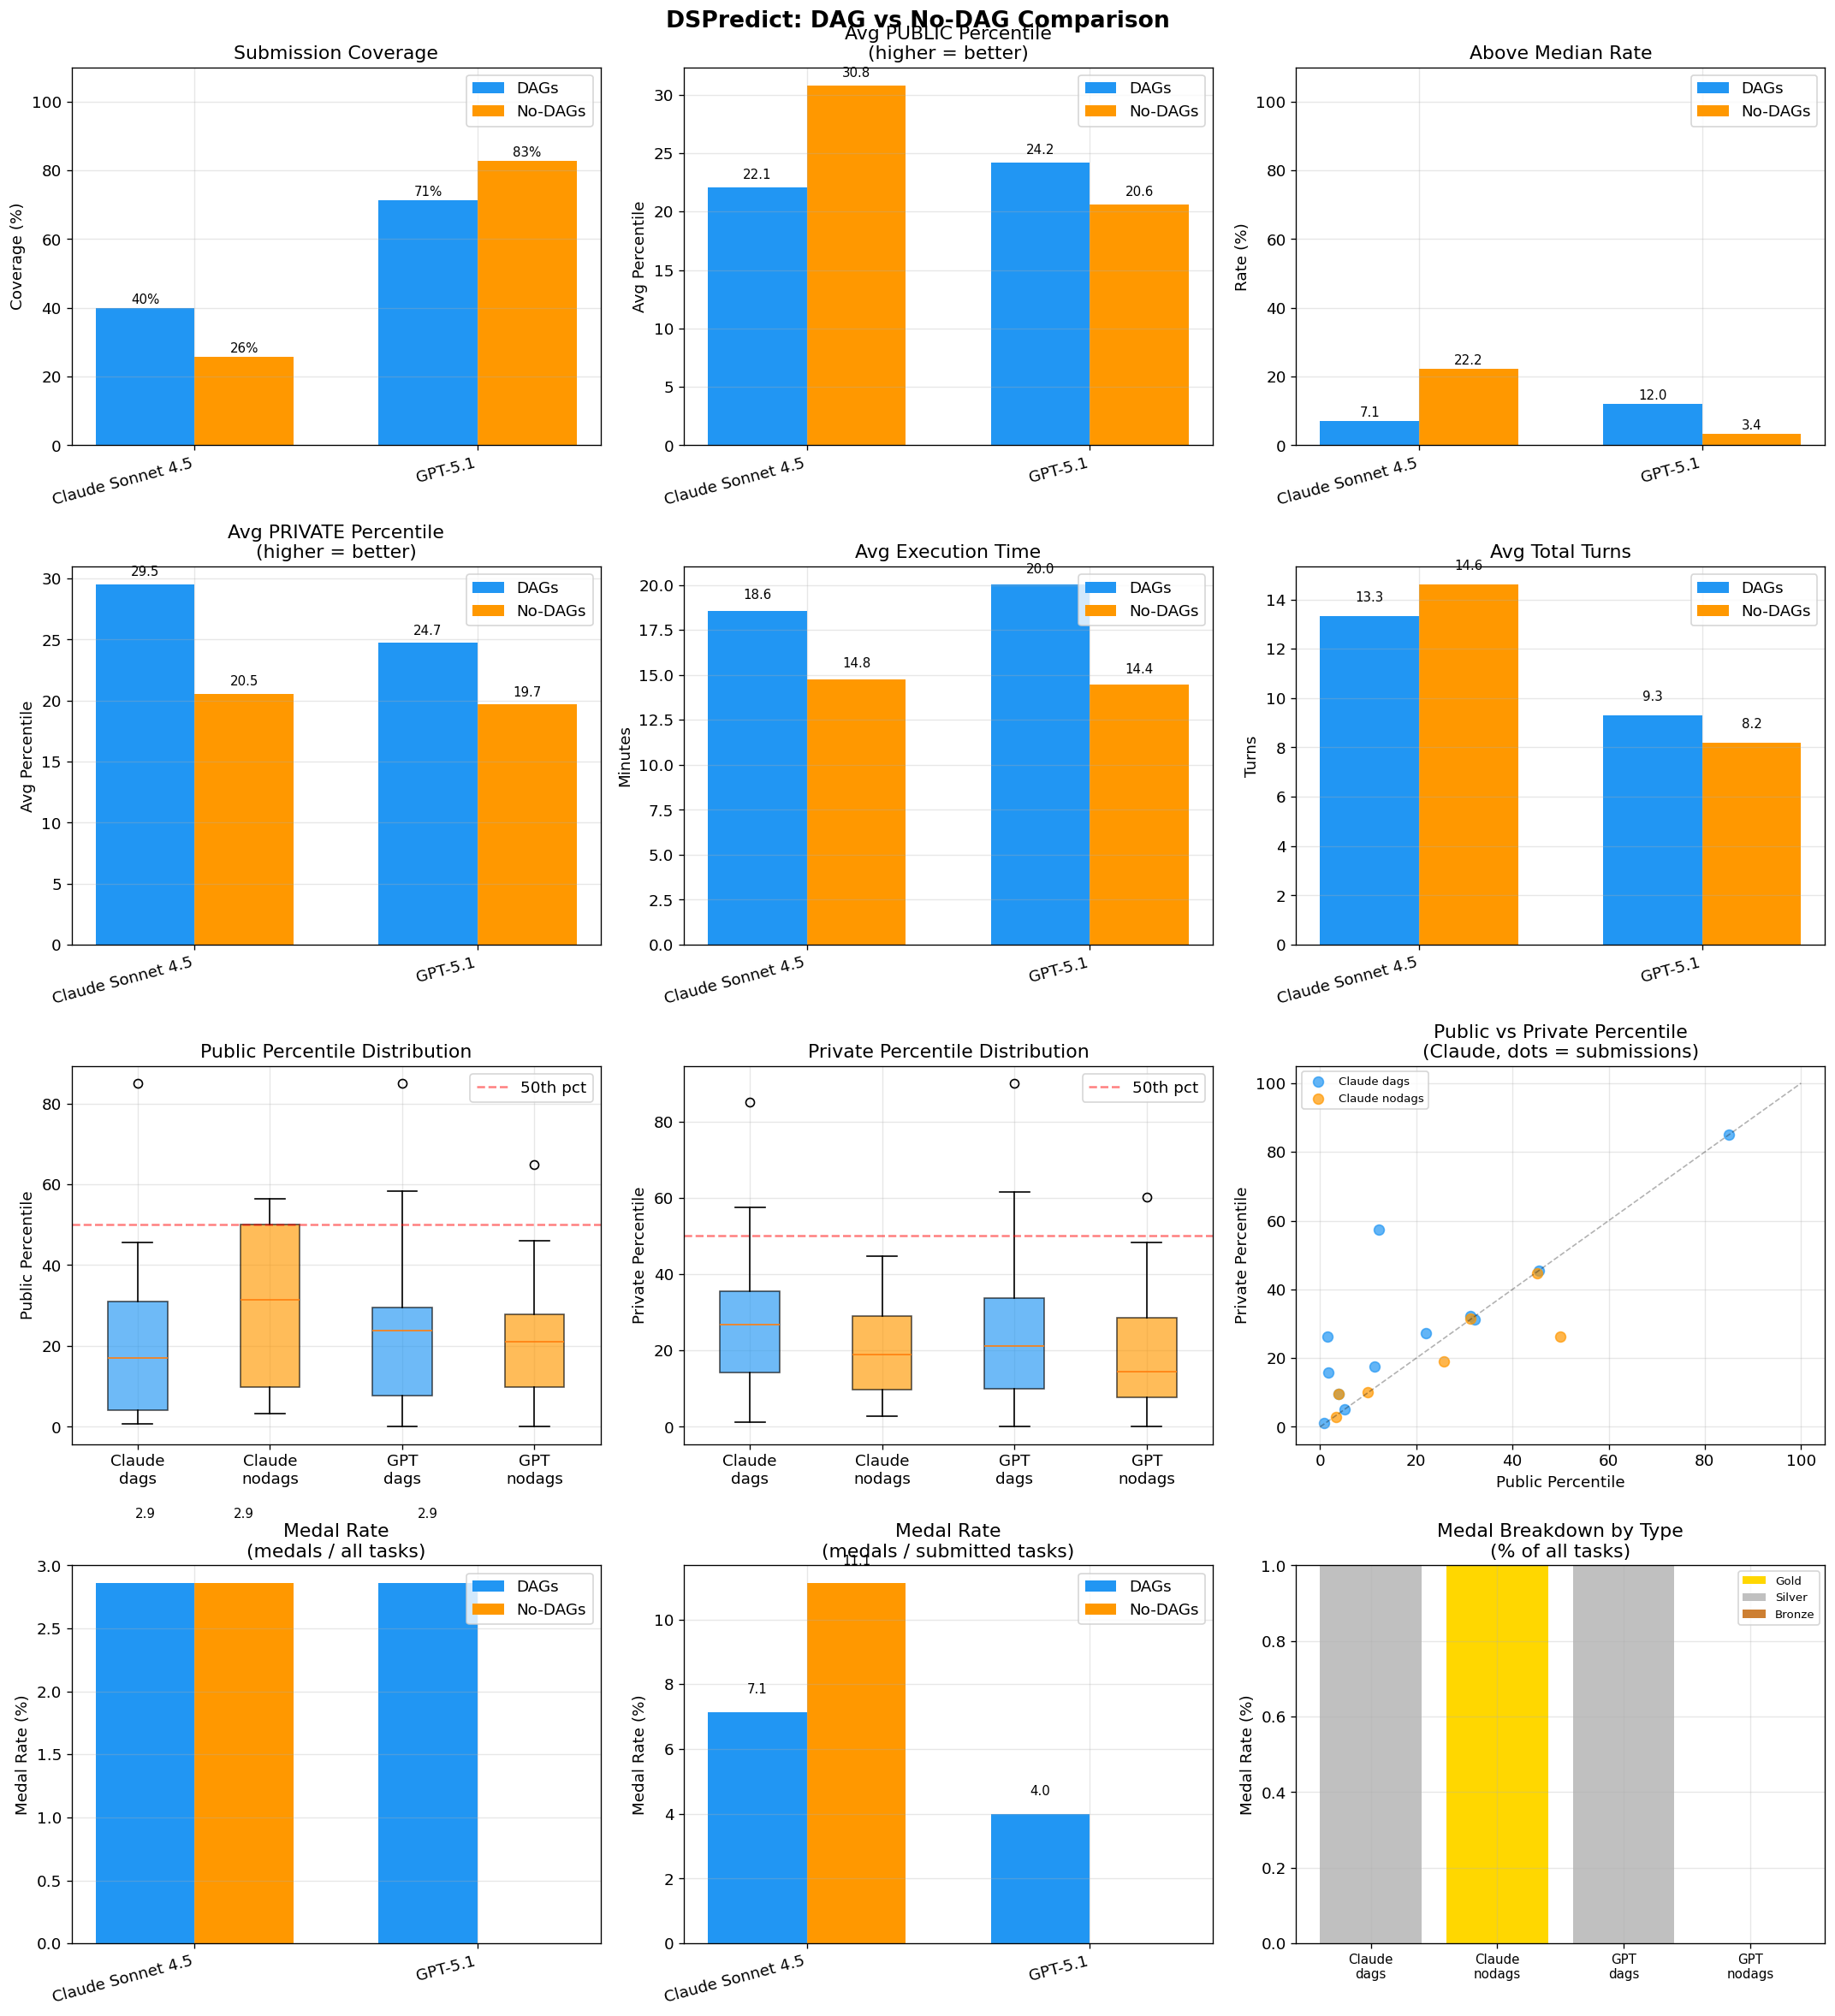

Saved dspredict_comparison.png


In [105]:
fig, axes = plt.subplots(4, 3, figsize=(18, 20))
fig.suptitle("DSPredict: DAG vs No-DAG Comparison", fontsize=16, fontweight="bold")

modes = ["dags", "nodags"]
x = np.arange(len(MODELS))
w = 0.35

def get_vals(fn):
    return {m: [fn(m, md) for md in modes] for m in MODELS}

def bar_pair(ax, vals, ylabel, title, ylim=None, fmt="{:.1f}"):
    b1 = ax.bar(x - w/2, [vals[m][0] for m in MODELS], w, label="DAGs",    color=COLORS["dags"])
    b2 = ax.bar(x + w/2, [vals[m][1] for m in MODELS], w, label="No-DAGs", color=COLORS["nodags"])
    ax.set_xticks(x)
    ax.set_xticklabels([MODEL_LABELS[m] for m in MODELS], rotation=15, ha="right")
    ax.set_ylabel(ylabel); ax.set_title(title); ax.legend()
    if ylim: ax.set_ylim(ylim)
    for bar in [*b1, *b2]:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.5,
                    fmt.format(h), ha="center", va="bottom", fontsize=9)

# Row 0 ── Coverage / Public percentile / Above-median
def cov(m, md):
    data = dp_data.get((m, md), [])
    sub  = [r for r in data if "COMPLETE" in str(r.get("status",""))]
    return 100 * len(sub) / max(1, len(data))

def avg_pub_pct(m, md):
    vals = [r["pub_percentile"] for r in dp_data.get((m,md),[]) if r.get("pub_percentile") is not None]
    return np.mean(vals) if vals else 0

def avg_priv_pct(m, md):
    vals = [r["priv_percentile"] for r in dp_data.get((m,md),[]) if r.get("priv_percentile") is not None]
    return np.mean(vals) if vals else 0

def above_med(m, md):
    above = [r["pub_above_med"] for r in dp_data.get((m,md),[]) if r.get("pub_above_med") is not None]
    return 100 * sum(above) / len(above) if above else 0

bar_pair(axes[0,0], get_vals(cov),         "Coverage (%)",         "Submission Coverage", ylim=(0,110), fmt="{:.0f}%")
bar_pair(axes[0,1], get_vals(avg_pub_pct), "Avg Percentile",       "Avg PUBLIC Percentile\n(higher = better)")
bar_pair(axes[0,2], get_vals(above_med),   "Rate (%)",             "Above Median Rate", ylim=(0,110))

# Row 1 ── Private percentile / avg time / avg turns
bar_pair(axes[1,0], get_vals(avg_priv_pct), "Avg Percentile",      "Avg PRIVATE Percentile\n(higher = better)")

def avg_time(m, md):
    times = [r["execution_time"]/60 for r in dp_data.get((m,md),[]) if r.get("execution_time") is not None]
    return np.mean(times) if times else 0

def avg_turns(m, md):
    turns = [r["total_turns"] for r in dp_data.get((m,md),[]) if r.get("total_turns") is not None]
    return np.mean(turns) if turns else 0

bar_pair(axes[1,1], get_vals(avg_time),  "Minutes", "Avg Execution Time")
bar_pair(axes[1,2], get_vals(avg_turns), "Turns",   "Avg Total Turns")

# Row 2 ── Public vs Private percentile distribution boxes (side by side)
for col, (pct_key, label) in enumerate([("pub_percentile", "Public"), ("priv_percentile", "Private")]):
    ax = axes[2, col]
    pct_data, box_labels = [], []
    for m in MODELS:
        for md in modes:
            vals = [r[pct_key] for r in dp_data.get((m,md),[]) if r.get(pct_key) is not None]
            pct_data.append(vals)
            box_labels.append(f"{'Claude' if 'claude' in m else 'GPT'}\n{md}")
    bp = ax.boxplot([d for d in pct_data], labels=box_labels, patch_artist=True)
    for patch, col_c in zip(bp["boxes"], [COLORS["dags"], COLORS["nodags"]] * 2):
        patch.set_facecolor(col_c); patch.set_alpha(0.65)
    ax.axhline(50, color="red", ls="--", alpha=0.5, label="50th pct")
    ax.set_ylabel(f"{label} Percentile"); ax.set_title(f"{label} Percentile Distribution"); ax.legend()

# Public vs Private scatter per sample (Claude dags only)
ax = axes[2, 2]
for (model, mode), color in [
    (("claude-sonnet-4-5","dags"),   COLORS["dags"]),
    (("claude-sonnet-4-5","nodags"), COLORS["nodags"]),
]:
    data = dp_data.get((model, mode), [])
    pub  = [r["pub_percentile"]  for r in data if r.get("pub_percentile")  and r.get("priv_percentile")]
    priv = [r["priv_percentile"] for r in data if r.get("pub_percentile")  and r.get("priv_percentile")]
    label = f"Claude {mode}"
    ax.scatter(pub, priv, alpha=0.7, color=color, label=label, s=50)
ax.plot([0,100],[0,100], "k--", alpha=0.3, lw=1)
ax.set_xlabel("Public Percentile"); ax.set_ylabel("Private Percentile")
ax.set_title("Public vs Private Percentile\n(Claude, dots = submissions)")
ax.legend(fontsize=8)

# Row 3 ── Medal rate (% of all tasks), medal rate of submitted, medal type breakdown
MEDAL_TYPES = ["gold", "silver", "bronze"]
MEDAL_COLORS = {"gold": "#FFD700", "silver": "#C0C0C0", "bronze": "#CD7F32", "none": "#DDDDDD"}

def medal_rate_all(m, md):
    """Medals earned / total tasks (%)"""
    data = dp_data.get((m, md), [])
    sub  = [r for r in data if "COMPLETE" in str(r.get("status", ""))]
    medals = [r["public_medal"] for r in sub if r.get("public_medal") not in (None, "none")]
    return 100 * len(medals) / max(1, len(data))

def medal_rate_submitted(m, md):
    """Medals earned / submitted tasks (%)"""
    data = dp_data.get((m, md), [])
    sub  = [r for r in data if "COMPLETE" in str(r.get("status", ""))]
    medals = [r["public_medal"] for r in sub if r.get("public_medal") not in (None, "none")]
    return 100 * len(medals) / max(1, len(sub))

bar_pair(axes[3, 0], get_vals(medal_rate_all),       "Medal Rate (%)", "Medal Rate\n(medals / all tasks)")
bar_pair(axes[3, 1], get_vals(medal_rate_submitted), "Medal Rate (%)", "Medal Rate\n(medals / submitted tasks)")

# Medal type breakdown (stacked bar)
ax = axes[3, 2]
x_pos = np.arange(len(MODELS) * 2)
tick_labels = [f"{'Claude' if 'claude' in m else 'GPT'}\n{md}" for m in MODELS for md in modes]
bottoms = np.zeros(len(x_pos))
for mtype in MEDAL_TYPES:
    heights = []
    for m in MODELS:
        for md in modes:
            data = dp_data.get((m, md), [])
            sub  = [r for r in data if "COMPLETE" in str(r.get("status", ""))]
            count = sum(1 for r in sub if r.get("public_medal") == mtype)
            heights.append(count)
    ax.bar(x_pos, heights, bottom=bottoms, color=MEDAL_COLORS[mtype], label=mtype.capitalize())
    bottoms += np.array(heights)
ax.set_xticks(x_pos)
ax.set_xticklabels(tick_labels, fontsize=9)
ax.set_ylabel("Medal Rate (%)")
ax.set_title("Medal Breakdown by Type\n(% of all tasks)")
ax.legend(fontsize=8)


plt.tight_layout()
plt.savefig(RESULTS_DIR / "dspredict_comparison.png", bbox_inches="tight", dpi=150)
plt.show()
print("Saved dspredict_comparison.png")


## 2 · DSBio Results

In [106]:
def load_dsbio(path):
    with open(path) as f:
        data = json.load(f)
    rows = []
    for item in data:
        em = item.get("metrics", {}).get("exact_match", {})
        rows.append({
            "sample_id":      item.get("sample_id"),
            "exact_match":    em.get("score"),
            "execution_time": item.get("execution_time"),
            "total_turns":    item.get("total_turns"),
            "success":        item.get("success"),
            "query_id":       item.get("extra_info", {}).get("query_id"),
            "trajectory":     item.get("trajectory", []),
        })
    return rows

bio_data = {}
for key, path in BIO_RUNS.items():
    if path.exists():
        bio_data[key] = load_dsbio(path)
        print(f"  {key[0]}/{key[1]}: {len(bio_data[key])} samples")
    else:
        print(f"  MISSING: {path}")

# Summary
bio_rows = []
for (model, mode), data in bio_data.items():
    em    = [r["exact_match"]    for r in data if r["exact_match"]    is not None]
    times = [r["execution_time"] for r in data if r["execution_time"] is not None]
    turns = [r["total_turns"]    for r in data if r["total_turns"]    is not None]
    succ  = [r["success"]        for r in data if r["success"]        is not None]
    bio_rows.append({
        "Model":               model,
        "Mode":                mode,
        "N":                   len(data),
        "Exact Match (%)":     round(100 * np.mean(em), 1) if em else None,
        "Success Rate (%)":    round(100 * sum(succ) / len(succ), 1) if succ else None,
        "Avg Time (s)":        round(np.mean(times), 1) if times else None,
        "Avg Turns":           round(np.mean(turns), 1) if turns else None,
    })
bio_sum = pd.DataFrame(bio_rows)
print("\n=== DSBio Run Summary ===")
display(bio_sum.set_index(["Model", "Mode"]))


  claude-sonnet-4-5/dags: 35 samples
  claude-sonnet-4-5/nodags: 35 samples
  gpt-5.1/dags: 35 samples
  gpt-5.1/nodags: 35 samples

=== DSBio Run Summary ===


N  Exact Match (%)  Success Rate (%)  Avg Time (s)  \
Model             Mode                                                          
claude-sonnet-4-5 dags    35             45.7              97.1         341.7   
                  nodags  35             40.0              51.4         273.0   
gpt-5.1           dags    35             17.1             100.0         434.9   
                  nodags  35             37.1              97.1         144.0   

                          Avg Turns  
Model             Mode               
claude-sonnet-4-5 dags          9.3  
                  nodags       12.7  
gpt-5.1           dags          4.0  
                  nodags        5.6

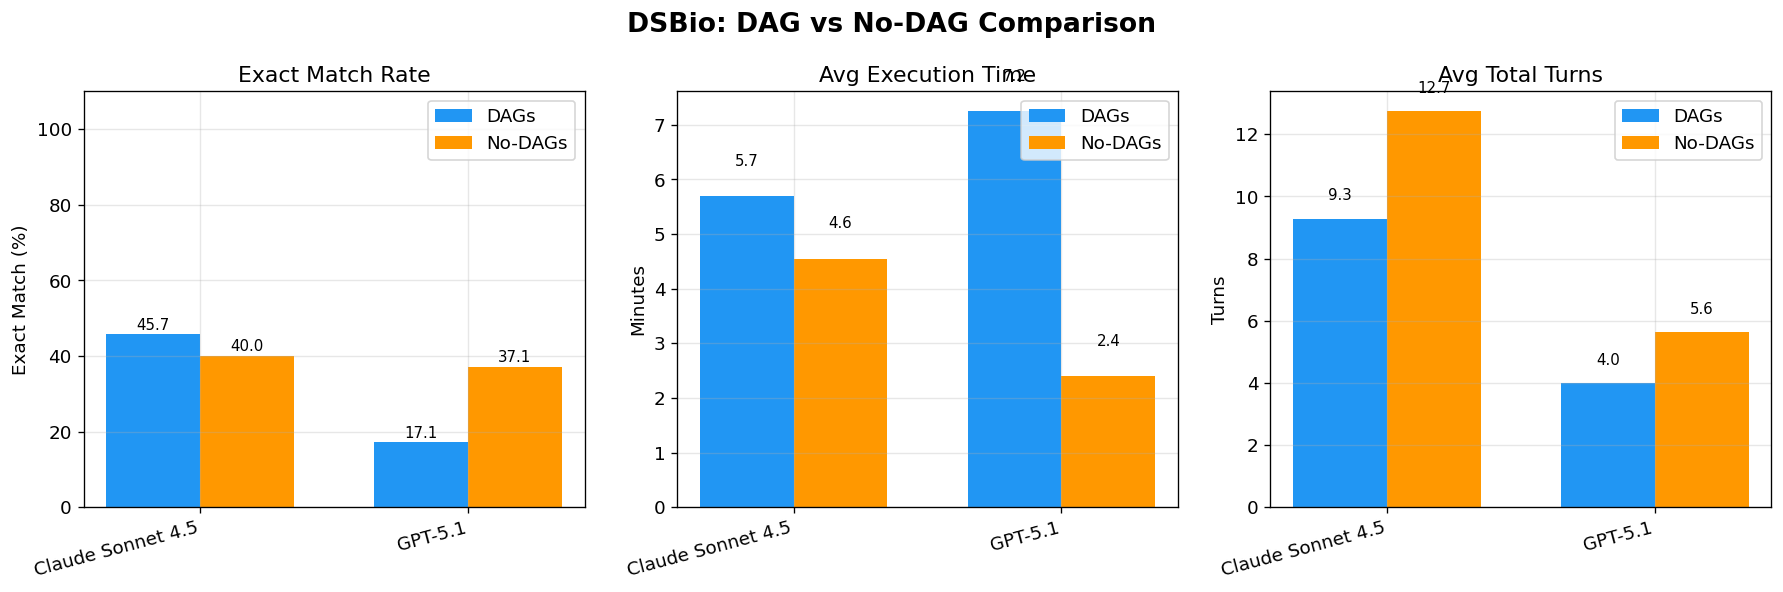

Saved dsbio_comparison.png


In [107]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("DSBio: DAG vs No-DAG Comparison", fontsize=16, fontweight="bold")
x = np.arange(len(MODELS)); w = 0.35

def bio_mean(m, md, key, scale=1.0):
    data = bio_data.get((m, md), [])
    vals = [r[key] for r in data if r.get(key) is not None]
    return scale * np.mean(vals) if vals else 0

for ax, (key, scale, ylabel, title) in zip(axes, [
    ("exact_match",    100,  "Exact Match (%)",  "Exact Match Rate"),
    ("execution_time", 1/60, "Minutes",           "Avg Execution Time"),
    ("total_turns",    1,    "Turns",             "Avg Total Turns"),
]):
    v_dags   = [bio_mean(m, "dags",   key, scale) for m in MODELS]
    v_nodags = [bio_mean(m, "nodags", key, scale) for m in MODELS]
    b1 = ax.bar(x - w/2, v_dags,   w, label="DAGs",    color=COLORS["dags"])
    b2 = ax.bar(x + w/2, v_nodags, w, label="No-DAGs", color=COLORS["nodags"])
    ax.set_xticks(x)
    ax.set_xticklabels([MODEL_LABELS[m] for m in MODELS], rotation=15, ha="right")
    ax.set_ylabel(ylabel); ax.set_title(title); ax.legend()
    if key == "exact_match":
        ax.set_ylim(0, 110)
    for bar in [*b1, *b2]:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.5,
                    f"{h:.1f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "dsbio_comparison.png", bbox_inches="tight", dpi=150)
plt.show()
print("Saved dsbio_comparison.png")


## 3 · DAG Structure Analysis

In [108]:
def extract_dags_from_trajectory(trajectory):
    """Parse JSON DAG blocks embedded in assistant turn content."""
    dags = []
    for turn in trajectory:
        if turn.get("role") != "assistant":
            continue
        for block in re.findall(r"```json\s*(.*?)\s*```", turn.get("content", ""), re.DOTALL):
            try:
                obj = json.loads(block)
                if isinstance(obj, dict) and "dag_type" in obj and "nodes" in obj:
                    dags.append({
                        "turn":     turn.get("turn"),
                        "dag_type": obj["dag_type"],
                        "nodes":    obj.get("nodes", []),
                        "edges":    obj.get("edges", []),
                        "graph_id": obj.get("graph_id", ""),
                    })
            except json.JSONDecodeError:
                pass
    return dags


def load_dag_dir(dag_dir):
    """Load pre-parsed DAG JSON files from dags/ subdirectory."""
    result = {}
    for fp in dag_dir.glob("*.json"):
        with open(fp) as f:
            d = json.load(f)
        result[(d.get("model",""), d.get("question_id",""))] = d
    return result


parsed_dags = load_dag_dir(DAG_DIR)
print(f"Pre-parsed DAG files: {len(parsed_dags)}")
for (model, qid), d in parsed_dags.items():
    print(f"  {model} / {qid}  —  {len(d.get('dags',[]))} dags, {d.get('n_revisions')} revisions")

# Collect trajectory-embedded DAGs from DSPredict dags runs
traj_dags = {}
for (model, mode), data in dp_data.items():
    if mode != "dags":
        continue
    for row in data:
        dags = extract_dags_from_trajectory(row.get("trajectory", []))
        if dags:
            traj_dags[(model, row["challenge"])] = dags

print(f"\nChallenges with embedded trajectory DAGs: {len(traj_dags)}")


Pre-parsed DAG files: 14
  gpt-5.1 / statoil-iceberg-classifier-challenge  —  2 dags, 0 revisions
  gpt-5.1 / ashrae-energy-prediction  —  2 dags, 0 revisions
  gpt-5.1 / 2  —  1 dags, 1 revisions
  gpt-5.1 / siim-acr-pneumothorax-segmentation  —  2 dags, 0 revisions
  gpt-5.1 / mens-machine-learning-competition-2018  —  2 dags, 0 revisions
  gpt-5.1 / 9  —  1 dags, 1 revisions
  claude-sonnet-4-5 / geolifeclef-2024  —  2 dags, 0 revisions
  gpt-5.1 / santander-value-prediction-challenge  —  3 dags, 0 revisions
  gpt-5.1 / 4  —  1 dags, 1 revisions
  gpt-5.1 / mens-march-mania-2022  —  3 dags, 0 revisions
  gpt-5.1 / career-con-2019  —  2 dags, 0 revisions
  gpt-5.1 / sp-society-camera-model-identification  —  1 dags, 1 revisions
  gpt-5.1 / imaterialist-challenge-fashion-2018  —  2 dags, 0 revisions
  claude-sonnet-4-5 / stanford-covid-vaccine  —  1 dags, 1 revisions

Challenges with embedded trajectory DAGs: 17


In [109]:
dag_stats = []
for (model, challenge), dags in traj_dags.items():
    reasoning = [d for d in dags if d["dag_type"] == "reasoning"]
    impl      = [d for d in dags if "implementation" in d["dag_type"]]
    revisions = [d for d in dags if "revision" in d["dag_type"]]
    dag_stats.append({
        "Model":           model,
        "Challenge":       challenge,
        "Total DAGs":      len(dags),
        "Reasoning":       len(reasoning),
        "Implementations": len(impl),
        "Revisions":       len(revisions),
        "Avg nodes (R)":   round(np.mean([len(d["nodes"]) for d in reasoning]), 1) if reasoning else 0,
        "Avg nodes (I)":   round(np.mean([len(d["nodes"]) for d in impl]),      1) if impl      else 0,
    })

dag_df = pd.DataFrame(dag_stats).sort_values(["Model", "Challenge"])
print("=== DAG Structure Statistics ===")
display(dag_df.set_index(["Model", "Challenge"]))


=== DAG Structure Statistics ===


Total DAGs  \
Model             Challenge                                               
claude-sonnet-4-5 LANL-Earthquake-Prediction                          2   
                  career-con-2019                                     2   
                  digit-recognizer                                    2   
                  gendered-pronoun-resolution                         2   
                  humpback-whale-identification                       2   
                  ieee-fraud-detection                                2   
                  imaterialist-challenge-fashion-2018                 2   
                  imaterialist-challenge-furniture-2018               2   
                  m5-forecasting-accuracy                             2   
                  mens-march-mania-2022                               2   
                  nlp-getting-started                                 2   
                  santander-customer-transaction-prediction           2   
                  santander-value-prediction-challenge                2   
                  siim-acr-pneumothorax-segmentation                  2   
                  trec-covid-information-retrieval                    2   
                  youtube8m-2019                                      2   
                  nan                                                 2   

                                                             Reasoning  \
Model             Challenge                                              
claude-sonnet-4-5 LANL-Earthquake-Prediction                         1   
                  career-con-2019                                    1   
                  digit-recognizer                                   1   
                  gendered-pronoun-resolution                        1   
                  humpback-whale-identification                      1   
                  ieee-fraud-detection                               1   
                  imaterialist-challenge-fashion-2018                1   
                  imaterialist-challenge-furniture-2018              1   
                  m5-forecasting-accuracy                            1   
                  mens-march-mania-2022                              1   
                  nlp-getting-started                                1   
                  santander-customer-transaction-prediction          1   
                  santander-value-prediction-challenge               1   
                  siim-acr-pneumothorax-segmentation                 1   
                  trec-covid-information-retrieval                   1   
                  youtube8m-2019                                     1   
                  nan                                                1   

                                                             Implementations  \
Model             Challenge                                                    
claude-sonnet-4-5 LANL-Earthquake-Prediction                               1   
                  career-con-2019                                          1   
                  digit-recognizer                                         1   
                  gendered-pronoun-resolution                              1   
                  humpback-whale-identification                            1   
                  ieee-fraud-detection                                     1   
                  imaterialist-challenge-fashion-2018                      1   
                  imaterialist-challenge-furniture-2018                    1   
                  m5-forecasting-accuracy                                  1   
                  mens-march-mania-2022                                    1   
                  nlp-getting-started                                      1   
                  santander-customer-transaction-prediction                1   
                  santander-value-prediction-challenge                     1   
                  siim-acr-p

In [110]:
dag_df["Challenge"]

13                   LANL-Earthquake-Prediction
6                               career-con-2019
4                              digit-recognizer
1                   gendered-pronoun-resolution
8                 humpback-whale-identification
7                          ieee-fraud-detection
3           imaterialist-challenge-fashion-2018
2         imaterialist-challenge-furniture-2018
11                      m5-forecasting-accuracy
14                        mens-march-mania-2022
9                           nlp-getting-started
10    santander-customer-transaction-prediction
15         santander-value-prediction-challenge
5            siim-acr-pneumothorax-segmentation
12             trec-covid-information-retrieval
16                               youtube8m-2019
0                                           NaN
Name: Challenge, dtype: str

In [111]:
import textwrap

def draw_dag(dag, ax, title=""):
    G = nx.DiGraph()
    node_labels = {}
    for n in dag.get("nodes", []):
        nid   = n["id"]
        label = n.get("label", nid)
        if len(label) > 70:
            label = label[:67] + "..."
        G.add_node(nid)
        node_labels[nid] = label

    for e in dag.get("edges", []):
        G.add_edge(e["source"], e["target"])

    if not G.nodes:
        ax.text(0.5, 0.5, "(empty)", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(title); ax.axis("off"); return

    try:
        pos = nx.nx_agraph.graphviz_layout(G, prog="dot")
    except Exception:
        pos = nx.spring_layout(G, seed=42)

    dtype = dag.get("dag_type", "")
    nc = "#90CAF9" if dtype == "reasoning" else ("#A5D6A7" if dtype == "implementation" else "#FFCC80")

    nx.draw_networkx_edges(G, pos, ax=ax, arrows=True, arrowstyle="->",
                           arrowsize=15, edge_color="#555", width=1.5,
                           connectionstyle="arc3,rad=0.05")
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=nc, node_size=700, alpha=0.9)
    wrapped = {n: "\n".join(textwrap.wrap(lbl, 22)) for n, lbl in node_labels.items() if n in G.nodes}
    nx.draw_networkx_labels(G, pos, labels=wrapped, ax=ax, font_size=6)
    ax.set_title(title, fontsize=9, fontweight="bold"); ax.axis("off")


### 3.1 · DSPredict trajectory DAGs (reasoning → implementation revisions)

challenge:  None


AttributeError: 'NoneType' object has no attribute 'replace'

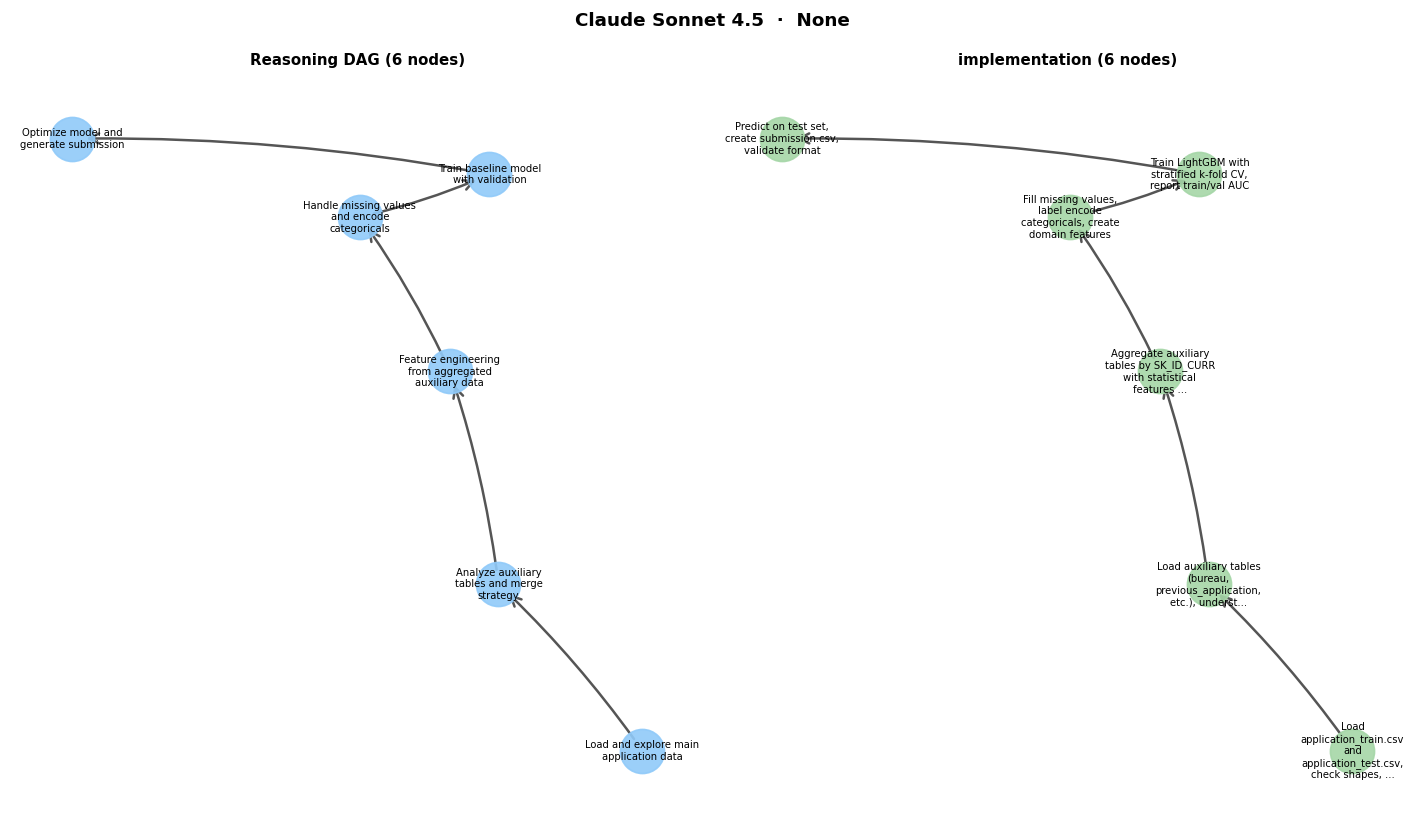

In [112]:
sample_keys = list(traj_dags.keys())

for (model, challenge) in sample_keys:
    print("challenge: ", challenge)
    dags      = traj_dags[(model, challenge)]
    reasoning = [d for d in dags if d["dag_type"] == "reasoning"]
    impl      = [d for d in dags if "implementation" in d["dag_type"]]

    n_cols = max(1, len(reasoning)) + len(impl)
    fig, axes = plt.subplots(1, n_cols, figsize=(min(6 * n_cols, 24), 7))
    if n_cols == 1:
        axes = [axes]

    fig.suptitle(f"{MODEL_LABELS.get(model, model)}  ·  {challenge}", fontsize=11, fontweight="bold")

    col = 0
    for d in reasoning:
        draw_dag(d, axes[col], f"Reasoning DAG ({len(d['nodes'])} nodes)")
        col += 1
    for d in impl:
        draw_dag(d, axes[col], f"{d['dag_type']} ({len(d['nodes'])} nodes)")
        col += 1
    while col < n_cols:
        axes[col].axis("off"); col += 1

    plt.tight_layout()
    safe = challenge.replace("/", "_")
    plt.savefig(RESULTS_DIR / f"dag_{model[:5]}_{safe}.png", bbox_inches="tight", dpi=120)
    plt.show()


## 4 · Cross-Benchmark Summary

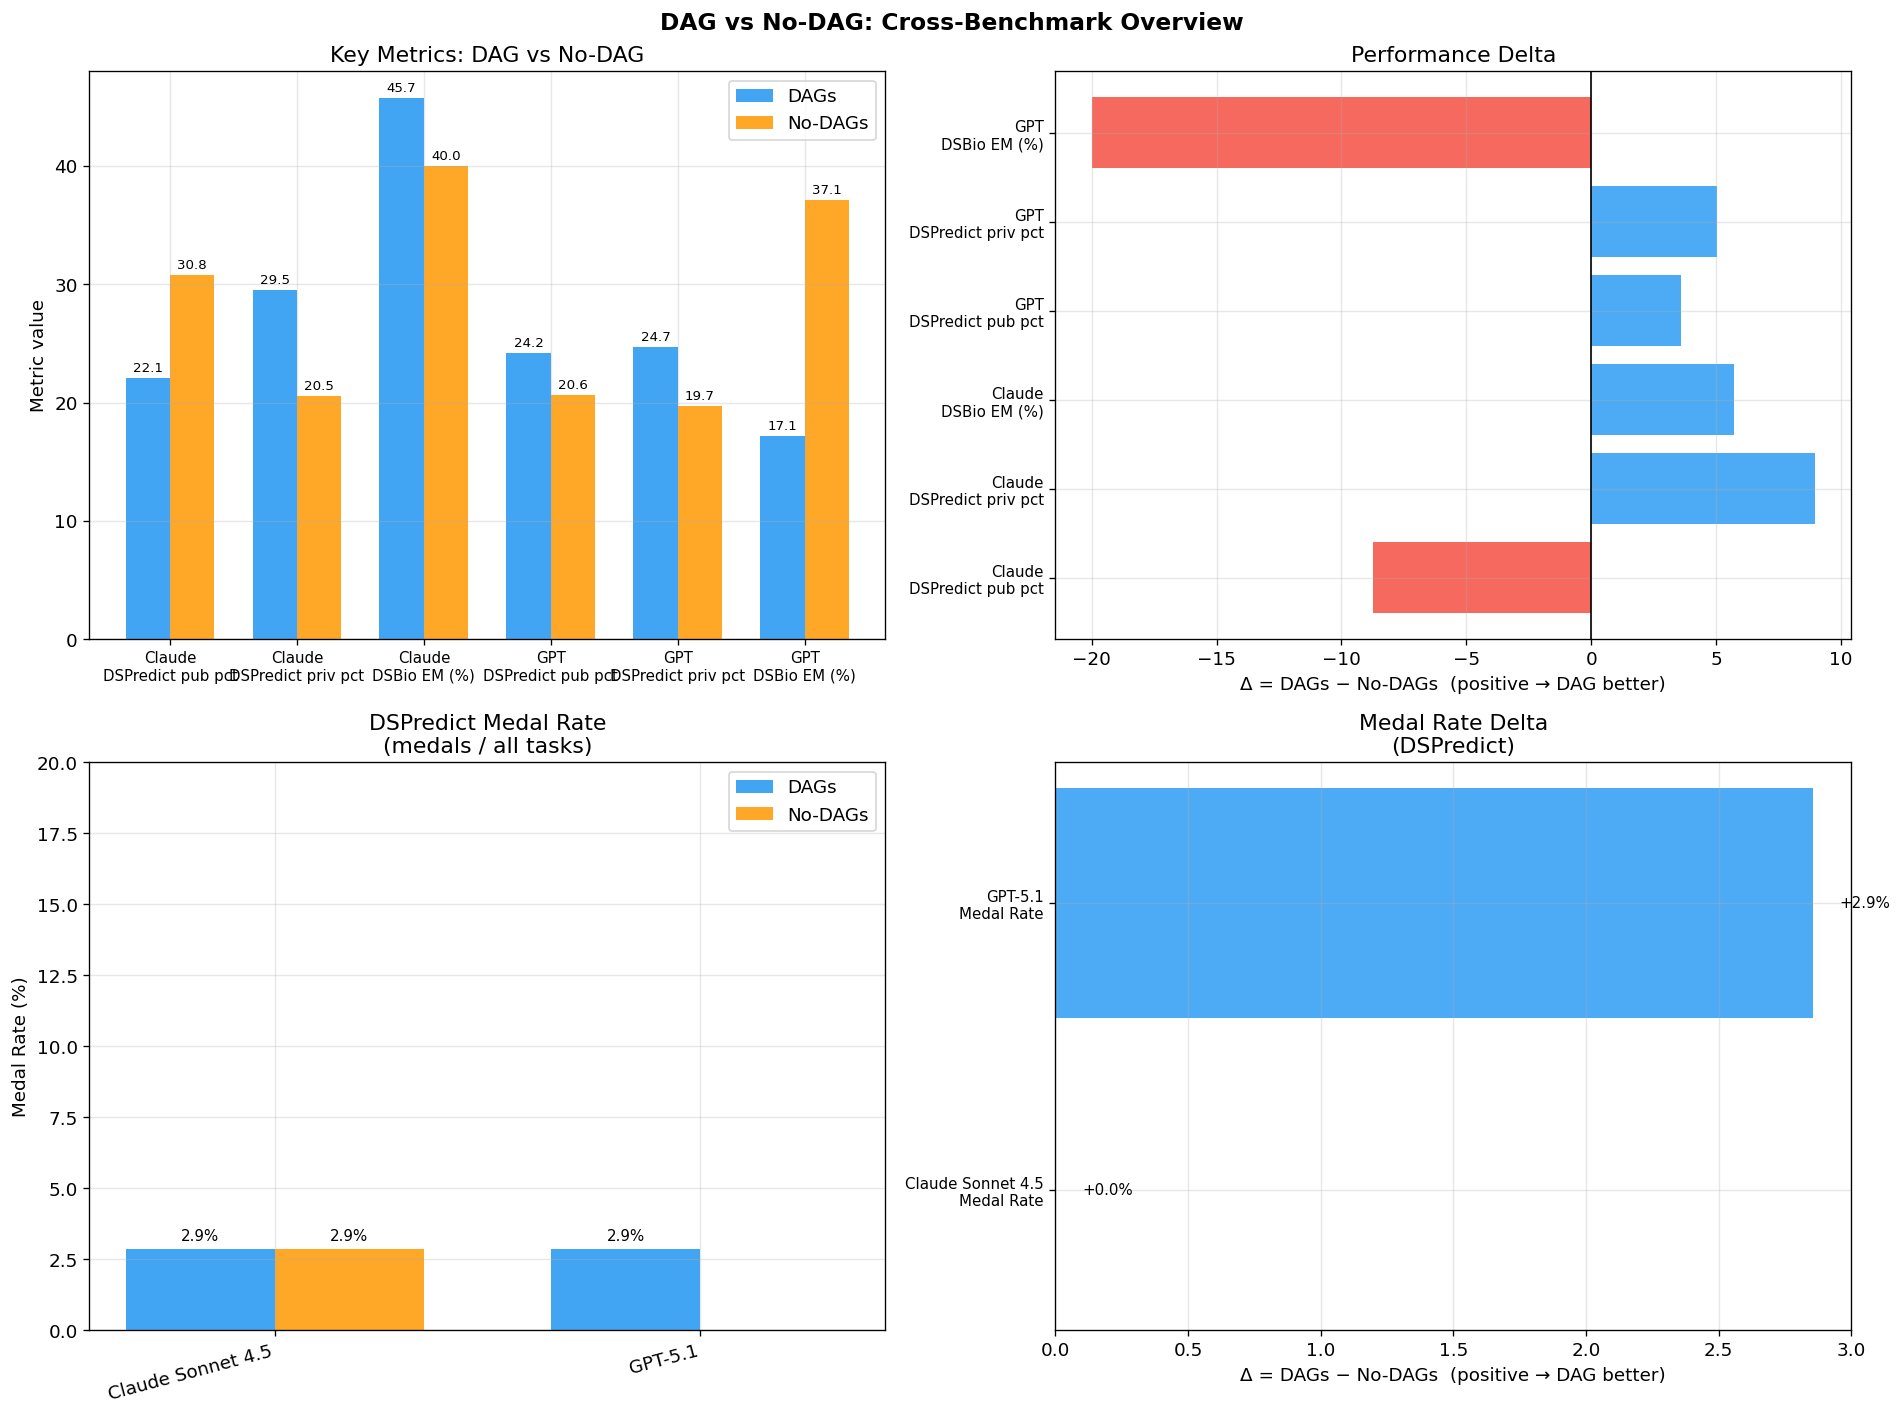


✓ All plots saved to evaluation_results/


In [113]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("DAG vs No-DAG: Cross-Benchmark Overview", fontsize=14, fontweight="bold")

# Build metric lists: [DSPredict-Pct-Claude, DSPredict-Pct-GPT, DSBio-EM-Claude, DSBio-EM-GPT]
metric_labels, dags_vals, nodags_vals = [], [], []
for model in MODELS:
    short = "Claude" if "claude" in model else "GPT"
    # DSPredict percentile
    dp_dag_pub   = [r["pub_percentile"] for r in dp_data.get((model,"dags"),   []) if r.get("pub_percentile") is not None]
    dp_dag_priv   = [r["priv_percentile"] for r in dp_data.get((model,"dags"),   []) if r.get("priv_percentile") is not None]

    dp_nodag_pub = [r["pub_percentile"] for r in dp_data.get((model,"nodags"), []) if r.get("pub_percentile") is not None]
    dp_nodag_priv = [r["priv_percentile"] for r in dp_data.get((model,"nodags"), []) if r.get("priv_percentile") is not None]

    metric_labels.append(f"{short}\nDSPredict pub pct")
    dags_vals.append(np.mean(dp_dag_pub)   if dp_dag_pub   else 0)
    nodags_vals.append(np.mean(dp_nodag_pub) if dp_nodag_pub else 0)

    metric_labels.append(f"{short}\nDSPredict priv pct")
    dags_vals.append(np.mean(dp_dag_priv)   if dp_dag_priv   else 0)
    nodags_vals.append(np.mean(dp_nodag_priv) if dp_nodag_priv else 0)

    # DSBio exact match
    bio_dag   = [r["exact_match"] for r in bio_data.get((model,"dags"),   []) if r.get("exact_match") is not None]
    bio_nodag = [r["exact_match"] for r in bio_data.get((model,"nodags"), []) if r.get("exact_match") is not None]
    metric_labels.append(f"{short}\nDSBio EM (%)")
    dags_vals.append(100 * np.mean(bio_dag)   if bio_dag   else 0)
    nodags_vals.append(100 * np.mean(bio_nodag) if bio_nodag else 0)

x = np.arange(len(metric_labels)); w = 0.35

# Left – grouped bar
ax = axes[0, 0]
b1 = ax.bar(x - w/2, dags_vals,   w, label="DAGs",    color=COLORS["dags"],   alpha=0.85)
b2 = ax.bar(x + w/2, nodags_vals, w, label="No-DAGs", color=COLORS["nodags"], alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(metric_labels, fontsize=9)
ax.set_ylabel("Metric value"); ax.set_title("Key Metrics: DAG vs No-DAG"); ax.legend()
for bar in [*b1, *b2]:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.3, f"{h:.1f}", ha="center", va="bottom", fontsize=8)

# Right – delta (DAG − No-DAG)
ax = axes[0, 1]
deltas = [d - n for d, n in zip(dags_vals, nodags_vals)]
bar_colors = ["#2196F3" if d >= 0 else "#F44336" for d in deltas]
ax.barh(range(len(metric_labels)), deltas, color=bar_colors, alpha=0.8)
ax.set_yticks(range(len(metric_labels))); ax.set_yticklabels(metric_labels, fontsize=9)
ax.set_xlabel("Δ = DAGs − No-DAGs  (positive → DAG better)")
ax.set_title("Performance Delta")
ax.axvline(0, color="black", lw=1)

# Row 1 left – grouped bar with medal rate added
ax = axes[1, 0]
medal_labels, medal_dags, medal_nodags = [], [], []
for model in MODELS:
    short = "Claude" if "claude" in model else "GPT"
    for md_label, mode in [("DAGs", "dags"), ("No-DAGs", "nodags")]:
        data = dp_data.get((model, mode), [])
        sub  = [r for r in data if "COMPLETE" in str(r.get("status", ""))]
        medals = [r["public_medal"] for r in sub if r.get("public_medal") not in (None, "none")]
        rate = 100 * len(medals) / max(1, len(data))
        medal_labels.append(f"{short}\n{md_label}")
        (medal_dags if mode == "dags" else medal_nodags).append(rate)

x2 = np.arange(len(MODELS)); w2 = 0.35
b1 = axes[1, 0].bar(x2 - w2/2, medal_dags,   w2, label="DAGs",    color=COLORS["dags"],   alpha=0.85)
b2 = axes[1, 0].bar(x2 + w2/2, medal_nodags, w2, label="No-DAGs", color=COLORS["nodags"], alpha=0.85)
axes[1, 0].set_xticks(x2)
axes[1, 0].set_xticklabels(["Claude Sonnet 4.5", "GPT-5.1"], rotation=15, ha="right")
axes[1, 0].set_ylabel("Medal Rate (%)")
axes[1, 0].set_title("DSPredict Medal Rate\n(medals / all tasks)")
axes[1, 0].legend()
axes[1, 0].set_ylim(0, 20)
for bar in [*b1, *b2]:
    h = bar.get_height()
    if h > 0:
        axes[1, 0].text(bar.get_x() + bar.get_width()/2, h + 0.2,
                        f"{h:.1f}%", ha="center", va="bottom", fontsize=9)

# Row 1 right – delta for medal rate
ax = axes[1, 1]
medal_deltas = [d - n for d, n in zip(medal_dags, medal_nodags)]
medal_bar_colors = ["#2196F3" if d >= 0 else "#F44336" for d in medal_deltas]
model_short_labels = ["Claude Sonnet 4.5\nMedal Rate", "GPT-5.1\nMedal Rate"]
ax.barh(range(len(MODELS)), medal_deltas, color=medal_bar_colors, alpha=0.8)
ax.set_yticks(range(len(MODELS)))
ax.set_yticklabels(model_short_labels, fontsize=9)
ax.set_xlabel("Δ = DAGs − No-DAGs  (positive → DAG better)")
ax.set_title("Medal Rate Delta\n(DSPredict)")
ax.axvline(0, color="black", lw=1)
for i, d in enumerate(medal_deltas):
    ax.text(d + (0.1 if d >= 0 else -0.1), i, f"{d:+.1f}%",
            ha="left" if d >= 0 else "right", va="center", fontsize=9)

# Move the original axes to row 0
# (already at axes[0] and axes[1] — need to reassign)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "cross_benchmark_comparison.png", bbox_inches="tight", dpi=150)
plt.show()
print("\n✓ All plots saved to evaluation_results/")
